# Batched iLQR: many tracking problems at once

Many applications solve the same optimal control problem for many datasets: one input trajectory per recorded
trial, or one per datapoint in every training step of an iLQR-VAE. Only a few leaves of the parameters change
from problem to problem (the observations, the reference trajectory, the initial state), while the model is
shared.

`diffilqrax.batch` maps the solvers over such a batch. This notebook checks that batched solves equal
one-at-a-time solves and measures wall-clock time on two datasets:

1. **Zebrafish tail bouts**: the six bouts of the MGU2 fixture, with the model of the
   [zebrafish reconstruction](zebrafish_tail_reconstruction.ipynb) notebook;
2. **Simulated tracking**: a tanh RNN tracking references simulated from the system itself with known
   inputs, for batch sizes up to 256.

**Why batching works now.** The solver has three nested loops: the iterations, the regularisation retries and
the line search. They run as `lax.while_loop`s (`loop="while"`, the default), so under `jax.vmap` the batch
stops once its slowest problem has converged. The older fixed-length `lax.scan` + `lax.cond` loops become
`select`s under `vmap`, so every problem paid for all `max_iter` iterations, every retry and every line-search
step. `while_loop` cannot be reverse-differentiated, but it doesn't need to be: `dilqr` and
`batch.batched_dilqr` differentiate the solution implicitly (see
[gradients through iLQR](gradients_through_ilqr.ipynb)).

In [1]:
import sys
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as onp

from diffilqrax import batch
from diffilqrax.diff_ilqr import dilqr
from diffilqrax.ilqr import ilqr_simulate, ilqr_solver
from diffilqrax.typs import ModelDims, System, Theta, iLQRParams

jax.config.update("jax_enable_x64", True)

TESTS = Path("../../../tests")
sys.path.insert(0, str(TESTS))
from mgu2_model import load_fixture, make_system, make_theta  # the model of the zebrafish notebook

print(f"jax {jax.__version__}, devices: {jax.devices()}")

jax 0.4.38, devices: [CpuDevice(id=0)]


## Timing

`timeit` compiles the function once (reported separately) and then reports the median wall-clock time of
`n_rep` runs of the compiled function. `jax.block_until_ready` waits for the asynchronous result.

In [2]:
def timeit(fn, *args, n_rep=3):
    t0 = time.perf_counter()
    compiled = jax.jit(fn).lower(*args).compile()
    t_compile = time.perf_counter() - t0
    times = []
    for _ in range(n_rep):
        t0 = time.perf_counter()
        out = jax.block_until_ready(compiled(*args))
        times.append(time.perf_counter() - t0)
    return out, t_compile, float(onp.median(times))


def n_iterations(history):
    # once converged the cost history repeats the final cost
    h = onp.asarray(history)
    return onp.array([int(onp.nonzero(row != row[-1])[0].max(initial=-1)) + 1 for row in h.reshape(-1, h.shape[-1])])


COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # validated categorical slots, in fixed order
MARKERS = ["o", "s", "^", "D"]

## 1. Zebrafish bouts

Only `theta.obs` differs between bouts. `in_axes` says so as a pytree prefix: 0 for the batched leaf, None for
the shared ones, as in `jax.vmap`. All bouts start from zero inputs, as in the reconstruction notebook.

In [3]:
ocaml_params, data = load_fixture(TESTS / "fixtures" / "ocaml_mgu.npz")
N_BEG = 12
all_obs = jnp.asarray(data["saved_tail"])  # (6, 160, 7)
theta = make_theta(ocaml_params, data["saved_tail"][0], N_BEG)
n, m, T = theta.uh.shape[0], theta.B.shape[0], data["ilqr_u"].shape[1]
fish = make_system(n, m, T)
fish_params = iLQRParams(x0=jnp.zeros(n), theta=theta)
fish_axes = (iLQRParams(x0=None, theta=jax.tree.map(lambda _: None, theta)._replace(obs=0)), None)
U0_fish = jnp.zeros((T, m))
KW = dict(max_iter=1000, alpha_init=2.0, kkt_tol=1e-6)


def fish_batch(obs):
    return fish_params._replace(theta=theta._replace(obs=obs))


def solve_one(obs):
    return ilqr_solver(fish, fish_batch(obs), U0_fish, **KW)


def solve_batch(obs, **kw):
    return batch.batched_ilqr_solver(fish, fish_batch(obs), U0_fish, fish_axes, **{**KW, **kw})


print(f"{all_obs.shape[0]} bouts, T={T}, latents n={n}, inputs m={m}")

6 bouts, T=171, latents n=120, inputs m=10


The reference is a Python loop over one compiled single-bout solve. The batched strategies are `lax.map`
(one bout at a time, or `batch_size` bouts vectorised together), `vmap`, and `vmap` with the parallel line
search. The parallel line search rolls out 8 step sizes at once and keeps the largest accepted one, so it
takes the same steps as backtracking.

In [4]:
solve_one_c = jax.jit(solve_one).lower(all_obs[0]).compile()
t0 = time.perf_counter()
loop_out = [jax.block_until_ready(solve_one_c(o)) for o in all_obs]
t_loop = time.perf_counter() - t0
(_, Us_loop, _), J_loop, hist_loop = jax.tree.map(lambda *xs: jnp.stack(xs), *loop_out)

fish_runs = {"python loop": (None, None, t_loop)}
strategies = {
    "lax.map": dict(strategy="map"),
    "lax.map, batch_size=3": dict(strategy="map", batch_size=3),
    "vmap": dict(strategy="vmap"),
    "vmap + parallel line search": dict(strategy="vmap", linesearch="parallel"),
}
if len(jax.devices()) > 1:
    strategies["shard"] = dict(strategy="shard")
for name, kw in strategies.items():
    fish_runs[name] = timeit(lambda obs, kw=kw: solve_batch(obs, **kw), all_obs, n_rep=1)

print(f"{'strategy':<30}{'compile (s)':>12}{'run (s)':>10}{'max |dU|':>11}{'max rel dJ':>12}")
for name, (out, t_c, t_r) in fish_runs.items():
    if out is None:
        print(f"{name:<30}{'':>12}{t_r:>10.1f}")
        continue
    (_, Us, _), J, _ = out
    dU = float(jnp.abs(Us - Us_loop).max())
    dJ = float(jnp.abs((J - J_loop) / J_loop).max())
    print(f"{name:<30}{t_c:>12.1f}{t_r:>10.1f}{dU:>11.1e}{dJ:>12.1e}")

strategy                       compile (s)   run (s)   max |dU|  max rel dJ
python loop                                     85.8
lax.map                                2.8      86.6    1.1e-15     1.8e-16
lax.map, batch_size=3                  7.1      85.3    2.0e-15     3.5e-16
vmap                                   4.3     107.1    4.6e-16     3.5e-16
vmap + parallel line search            5.2     121.2    3.5e-15     1.8e-16


Every batched strategy reaches the per-bout solutions, to round-off. With only six bouts of very different
lengths (see section 3), vectorising gains little on a CPU: `vmap` costs about as much as the loop, because
every bout waits for the slowest one. Its advantage is on many problems (section 2), on GPU, and in training,
where the batch must be solved inside one compiled, differentiable step. Against the OCaml reference the costs agree as in the
reconstruction notebook: bouts with a non-zero difference stopped in another local optimum of the non-convex
objective.

In [6]:
rel_ocaml = onp.abs(onp.asarray(J_loop) - data["ilqr_cost"]) / onp.abs(data["ilqr_cost"])
iters_fish = n_iterations(hist_loop)
print(f"{'bout':<6}{'cost':>12}{'OCaml':>12}{'rel diff':>10}{'iterations':>12}")
for b in range(all_obs.shape[0]):
    print(f"{b:<6}{float(J_loop[b]):>12.3f}{data['ilqr_cost'][b]:>12.3f}{rel_ocaml[b]:>10.1e}{iters_fish[b]:>12}")

bout          cost       OCaml  rel diff  iterations
0       -10188.690  -10215.129   2.6e-03          54
1       -10302.552  -10297.255   5.1e-04          51
2       -10263.757  -10270.089   6.2e-04          77
3       -10544.964  -10545.906   8.9e-05          40
4       -10313.109  -10312.940   1.6e-05          40
5       -10403.917  -10403.917   9.0e-14          53


**The cost of the old loops.** With `loop="scan"` the same `vmap` executes every iteration, retry and
line-search step for every bout. At an equal budget of 20 iterations, which no bout reaches convergence in,
both versions do the same number of outer iterations, so the gap is the inner loops alone.

In [7]:
short = dict(strategy="vmap", max_iter=20)
_, _, t_while20 = timeit(lambda obs: solve_batch(obs, **short), all_obs, n_rep=1)
_, _, t_scan20 = timeit(lambda obs: solve_batch(obs, loop="scan", **short), all_obs, n_rep=1)
print(f"vmap, 20 iterations: while {t_while20:.1f} s, scan {t_scan20:.1f} s ({t_scan20 / t_while20:.0f}x slower)")

vmap, 20 iterations: while 35.6 s, scan 327.6 s (9x slower)


## 2. Simulated tracking problems

A tanh RNN $x_{t+1} = \tanh(U_h x_t + W_h u_t)$ with $n=8$ latents and $m=3$ inputs tracks references
$\bar x^{(b)}$ that it generated itself from smooth random inputs $\bar u^{(b)}$ and random initial states.
The cost is $\sum_t \|x_t - \bar x^{(b)}_t\|^2 + 10^{-3}\|u_t\|^2$. Because the references are reachable,
the solution should recover the true inputs. The references sit in `theta.Q` and the initial states in
`x0`, the batched leaves.

In [8]:
n_r, m_r, T_r = 8, 3, 50
k1, k2, k3, k4, k5 = jax.random.split(jax.random.PRNGKey(0), 5)
rnn_theta = Theta(
    Uh=1.2 * jax.random.normal(k1, (n_r, n_r)) / jnp.sqrt(n_r),
    Wh=jax.random.normal(k2, (n_r, m_r)) / jnp.sqrt(n_r),
    sigma=jnp.zeros(n_r),
    Q=jnp.zeros((T_r + 1, n_r)),  # replaced by the references
)
rnn_dynamics = lambda t, x, u, th: jnp.tanh(th.Uh @ x + th.Wh @ u)
rnn = System(
    lambda t, x, u, th: jnp.sum((x - th.Q[t]) ** 2) + 1e-3 * jnp.sum(u**2),
    lambda x, th: jnp.sum((x - th.Q[-1]) ** 2),
    rnn_dynamics,
    ModelDims(horizon=T_r, n=n_r, m=m_r, dt=0.1),
)
rnn_axes = (iLQRParams(x0=0, theta=Theta(Uh=None, Wh=None, sigma=None, Q=0)), None)
U0_rnn = jnp.zeros((T_r, m_r))


def simulate_references(n_batch, key=k3):
    ka, kb, kc = jax.random.split(key, 3)
    x0s = 0.5 * jax.random.normal(ka, (n_batch, n_r))
    t = jnp.arange(T_r)[None, :, None, None]
    freqs = jnp.arange(1, 4)[None, None, None, :]
    amps = 0.5 * jax.random.normal(kb, (n_batch, 1, m_r, 3)) / freqs
    phases = jax.random.uniform(kc, (n_batch, 1, m_r, 3), maxval=2 * jnp.pi)
    Us_true = jnp.sum(amps * jnp.sin(2 * jnp.pi * freqs * t / T_r + phases), axis=-1)
    refs = jax.vmap(lambda x0, us: ilqr_simulate(rnn, us, iLQRParams(x0, rnn_theta))[0][0])(x0s, Us_true)
    return iLQRParams(x0=x0s, theta=rnn_theta._replace(Q=refs)), Us_true


rnn_params, Us_true = simulate_references(256)


def take(p, B):
    # the first B problems of a batch
    return iLQRParams(p.x0[:B], p.theta._replace(Q=p.theta.Q[:B]))

First a correctness check on 16 problems: the vmapped solve equals the one-at-a-time solves, every problem
converges, and the inputs are recovered.

converged: 16/16, max |U_vmap - U_one| = 1.0e-15
relative input error: median 3.0e-03, max 1.1e-02


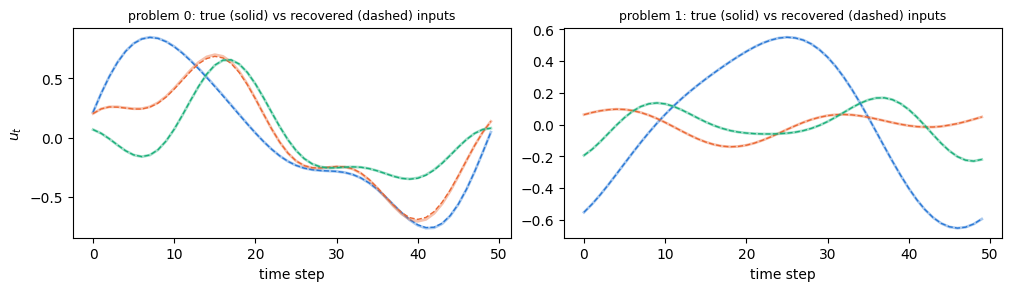

In [9]:
p16 = take(rnn_params, 16)
(Xs, Us, _), J, hist, conv = batch.batched_ilqr_solver(rnn, p16, U0_rnn, rnn_axes, max_iter=200, return_converged=True)
one = jax.jit(lambda p: ilqr_solver(rnn, p, U0_rnn, max_iter=200))
Us_one = jnp.stack([one(iLQRParams(p16.x0[b], p16.theta._replace(Q=p16.theta.Q[b])))[0][1] for b in range(16)])
rel_u = jnp.linalg.norm(Us - Us_true[:16], axis=(1, 2)) / jnp.linalg.norm(Us_true[:16], axis=(1, 2))
print(f"converged: {int(conv.sum())}/16, max |U_vmap - U_one| = {float(jnp.abs(Us - Us_one).max()):.1e}")
print(f"relative input error: median {float(jnp.median(rel_u)):.1e}, max {float(rel_u.max()):.1e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), layout="constrained")
for ax, b in zip(axes, [0, 1]):
    for j in range(m_r):
        ax.plot(Us_true[b, :, j], c=COLORS[j], lw=2, alpha=0.4)
        ax.plot(Us[b, :, j], c=COLORS[j], lw=1, ls="--")
    ax.set(title=f"problem {b}: true (solid) vs recovered (dashed) inputs", xlabel="time step")
    ax.title.set_fontsize(9)
axes[0].set_ylabel("$u_t$");

### Scaling with the batch size

Wall time of a Python loop over one compiled solve, `lax.map` and `vmap`, for batch sizes 1 to 256. The loop
and `lax.map` cost the same per problem at every size. `vmap` amortises the per-iteration overhead of these
small problems over the batch, so its cost per problem falls until the vectorised work dominates.

In [10]:
sizes = [1, 4, 16, 64, 256]
rnn_kw = dict(max_iter=200)
one_c = jax.jit(lambda p: ilqr_solver(rnn, p, U0_rnn, **rnn_kw))
scaling = {"python loop": [], "lax.map": [], "vmap": []}
rnn_hist = {}
for B in sizes:
    pB = take(rnn_params, B)
    singles = [iLQRParams(pB.x0[b], pB.theta._replace(Q=pB.theta.Q[b])) for b in range(B)]
    jax.block_until_ready(one_c(singles[0]))  # compile
    t0 = time.perf_counter()
    for p in singles:
        jax.block_until_ready(one_c(p))
    scaling["python loop"].append(time.perf_counter() - t0)
    for name, strat in [("lax.map", "map"), ("vmap", "vmap")]:
        out, _, t_r = timeit(lambda p, s=strat: batch.batched_ilqr_solver(rnn, p, U0_rnn, rnn_axes, strategy=s, **rnn_kw), pB)
        scaling[name].append(t_r)
    rnn_hist[B] = out[2]

print(f"{'B':>5}" + "".join(f"{k:>14}" for k in scaling))
for i, B in enumerate(sizes):
    print(f"{B:>5}" + "".join(f"{scaling[k][i]:>13.3f}s" for k in scaling))

    B   python loop       lax.map          vmap
    1        0.038s        0.035s        0.036s
    4        0.134s        0.140s        0.070s
   16        0.549s        0.573s        0.201s
   64        2.228s        2.255s        0.835s
  256        8.880s        8.705s        3.375s


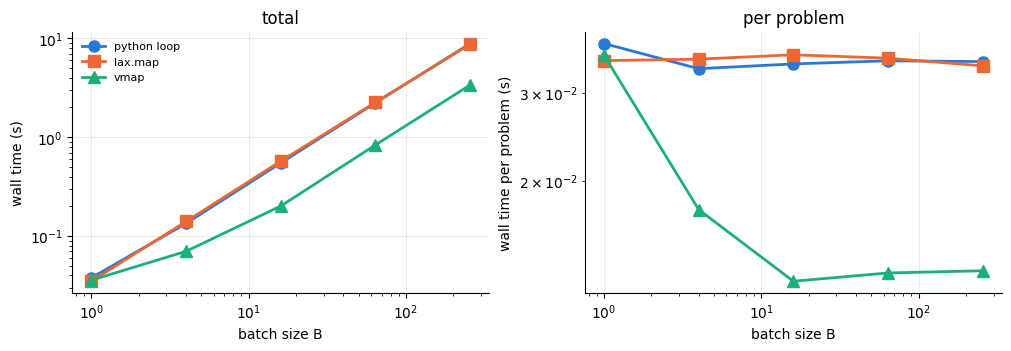

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
for c, (name, ts) in enumerate(scaling.items()):
    ts = onp.asarray(ts)
    for ax, y in zip(axes, [ts, ts / onp.asarray(sizes)]):
        ax.plot(sizes, y, c=COLORS[c], lw=2, marker=MARKERS[c], ms=8, label=name)
axes[0].set(xscale="log", yscale="log", xlabel="batch size B", ylabel="wall time (s)", title="total")
axes[1].set(xscale="log", yscale="log", xlabel="batch size B", ylabel="wall time per problem (s)", title="per problem")
for ax in axes:
    ax.grid(True, which="major", c="0.9", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8);

## 3. Lockstep efficiency

Under `vmap` the batch runs until its slowest problem has converged, and finished problems wait. The
efficiency is the mean number of iterations over the maximum: the fraction of the vectorised work that was
needed. `lax.map` with `batch_size`, or sharding over devices, limits the waiting to one chunk.

zebrafish (6 bouts)            iterations 40-77, efficiency mean/max = 68%
simulated RNN (256 problems)   iterations 33-42, efficiency mean/max = 88%


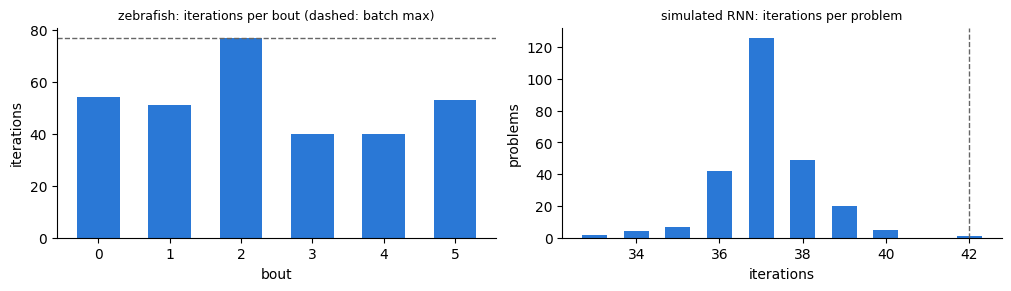

In [12]:
iters_rnn = n_iterations(rnn_hist[256])
for name, its in [("zebrafish (6 bouts)", iters_fish), ("simulated RNN (256 problems)", iters_rnn)]:
    print(f"{name:<30} iterations {its.min()}-{its.max()}, efficiency mean/max = {its.mean() / its.max():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), layout="constrained")
axes[0].bar(onp.arange(len(iters_fish)), iters_fish, color=COLORS[0], width=0.6)
axes[0].axhline(iters_fish.max(), c="0.4", lw=1, ls="--")
axes[0].set(xlabel="bout", ylabel="iterations", title="zebrafish: iterations per bout (dashed: batch max)")
counts = onp.bincount(iters_rnn)
its = onp.nonzero(counts)[0]
axes[1].bar(its, counts[its], color=COLORS[0], width=0.6)
axes[1].axvline(iters_rnn.max(), c="0.4", lw=1, ls="--")
axes[1].set(xlabel="iterations", ylabel="problems", title="simulated RNN: iterations per problem")
for ax in axes:
    ax.title.set_fontsize(9)
    ax.spines[["top", "right"]].set_visible(False)

## 4. Gradients through a batch

`batch.batched_dilqr` returns the optimal trajectories with implicit gradients. The batch is solved without
gradients, then each solution gets its gradient from one LQR solve. Reverse mode never enters the while
loops, so `jax.grad` of a loss summed over the batch works with every strategy. Here the gradient wrt the
shared recurrent weights equals the sum of the per-problem `dilqr` gradients.

In [13]:
p4 = take(rnn_params, 4)


def batch_loss(Uh, strategy):
    p = p4._replace(theta=p4.theta._replace(Uh=Uh))
    return jnp.sum(batch.batched_dilqr(rnn, p, U0_rnn, rnn_axes, strategy=strategy, max_iter=200) ** 2)


def single_loss(Uh, b):
    p = iLQRParams(p4.x0[b], p4.theta._replace(Uh=Uh, Q=p4.theta.Q[b]))
    return jnp.sum(dilqr(rnn, p, U0_rnn, max_iter=200) ** 2)


g_sum = sum(jax.grad(single_loss)(rnn_theta.Uh, b) for b in range(4))
for strategy in ["vmap", "map"]:
    g = jax.jit(jax.grad(batch_loss), static_argnums=1)(rnn_theta.Uh, strategy)
    print(f"{strategy:<5} relative difference to the summed gradients: {float(jnp.linalg.norm(g - g_sum) / jnp.linalg.norm(g_sum)):.1e}")

vmap  relative difference to the summed gradients: 8.4e-16
map   relative difference to the summed gradients: 1.5e-16


## How to adapt

- **Choosing a strategy.** On CPU, `lax.map` (`strategy="map"`, optionally with `batch_size`) avoids
  vectorised work on finished problems; `vmap` pays off when the problems are small and many, or on GPU, where
  the vectorised work is cheap and the sequential loop is not. On several devices `strategy="shard"` splits
  the batch with `shard_map`, so each device stops on its own shard. After `jax.distributed.initialize()`,
  `jax.devices()` spans every host.
- **Parallel line search.** `linesearch="parallel"` replaces up to `n_parallel` sequential rollouts by one
  vectorised rollout. It mostly helps on GPU; on CPU it does extra work.
- **Warm starts.** In training, start each problem from its previous solution. The iteration counts then
  shrink and even out, which improves the lockstep efficiency of `vmap`.
- **Convergence.** Implicit gradients assume converged solutions. `return_converged=True` returns a
  per-problem flag to check or mask with.